In [1]:
import time
import networkx as nx, pandas as pd, numpy as np

G = nx.read_edgelist("../data/facebook_combined.txt.gz", nodetype=int)
G.remove_edges_from(nx.selfloop_edges(G))
labels = pd.read_csv("../data/louvain_labels.csv").set_index("node")["community"].to_dict()

t = time.time()
df = pd.DataFrame({
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G, k=500, seed=42),
    "closeness": nx.closeness_centrality(G),
    "pagerank": nx.pagerank(G),
})
print("Thời gian tính:", round(time.time() - t, 1), "giây")

df["bac"] = [G.degree(n) for n in df.index]
df["community"] = df.index.map(labels)
df["so_cd_lan_can"] = [len({labels[m] for m in G[n]}) for n in df.index]
df.to_csv("../data/centrality.csv")

cols = ["bac", "community", "so_cd_lan_can"]
for c in ["degree", "betweenness", "closeness", "pagerank"]:
    print("\nTop 10 theo", c)
    print(df.nlargest(10, c)[[c] + cols].round(5).to_string())

print("\nTương quan Spearman:")
print(df[["degree", "betweenness", "closeness", "pagerank"]].corr(method="spearman").round(3))

Thời gian tính: 132.1 giây

Top 10 theo degree
       degree   bac  community  so_cd_lan_can
107   0.25879  1045          2              8
1684  0.19614   792          1              6
1912  0.18697   755          4              6
3437  0.13546   547          0              3
0     0.08593   347          5              4
2543  0.07281   294          7              2
2347  0.07207   291          7              2
1888  0.06290   254          2              2
1800  0.06067   245          2              3
1663  0.05820   235          2              2

Top 10 theo betweenness
      betweenness   bac  community  so_cd_lan_can
107       0.48971  1045          2              8
1684      0.34454   792          1              6
3437      0.22223   547          0              3
1912      0.21632   755          4              6
0         0.16145   347          5              4
1085      0.15030    66          0              4
698       0.11361    68          9              2
567       0.08815    6

   p           Hạt giống  Số nút kích hoạt TB
0.02              degree                891.3
0.02         betweenness                921.5
0.02           closeness                711.8
0.02            pagerank                936.2
0.02 ngẫu nhiên (20 tập)                542.0
0.05              degree               2152.9
0.05         betweenness               2195.6
0.05           closeness               1980.6
0.05            pagerank               2232.4
0.05 ngẫu nhiên (20 tập)               2035.9
Thời gian: 40 giây


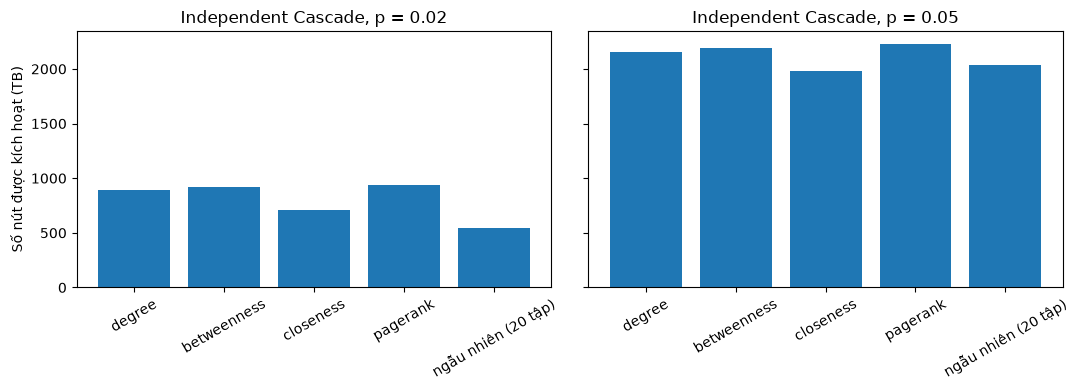

In [2]:
import random, time
import matplotlib.pyplot as plt

df = pd.read_csv("../data/centrality.csv", index_col=0)
K, RUNS = 10, 100

def cascade(seeds, p, rng):
    active = set(seeds); frontier = list(seeds)
    while frontier:
        new = []
        for u in frontier:
            for v in G[u]:
                if v not in active and rng.random() < p:
                    active.add(v); new.append(v)
        frontier = new
    return len(active)

def mean_spread(seeds, p, runs, seed=0):
    rng = random.Random(seed)
    return np.mean([cascade(seeds, p, rng) for _ in range(runs)])

configs = {c: list(df.nlargest(K, c).index)
           for c in ["degree", "betweenness", "closeness", "pagerank"]}
nodes = list(G.nodes())

t = time.time()
rows = []
for p in [0.02, 0.05]:
    for name, seeds in configs.items():
        rows.append({"p": p, "Hạt giống": name, "Số nút kích hoạt TB": round(mean_spread(seeds, p, RUNS), 1)})
    rs = random.Random(1)
    rnd = [mean_spread(rs.sample(nodes, K), p, 20, seed=i) for i in range(20)]
    rows.append({"p": p, "Hạt giống": "ngẫu nhiên (20 tập)", "Số nút kích hoạt TB": round(np.mean(rnd), 1)})
kq = pd.DataFrame(rows)
print(kq.to_string(index=False))
print("Thời gian:", round(time.time() - t), "giây")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, p in zip(ax, [0.02, 0.05]):
    s = kq[kq.p == p]
    a.bar(s["Hạt giống"], s["Số nút kích hoạt TB"])
    a.set_title(f"Independent Cascade, p = {p}")
    a.tick_params(axis="x", rotation=30)
ax[0].set_ylabel("Số nút được kích hoạt (TB)")
plt.tight_layout()
plt.savefig("../figures/ic_spread.png", dpi=200)
plt.show()